# 03 — Assemblage REP 17×17 : carte de puissance et convergence de la source

**Objectifs**
1. Modéliser un **assemblage de type Westinghouse 17×17** : 264 crayons combustibles, 24 tubes guides et un tube
   d'instrumentation central.
2. Calculer la **carte de puissance crayon par crayon**, avec ses incertitudes, et le facteur de point chaud.
3. Étudier la **convergence de la source de fission**, sujet de l'exemple officiel *Source Convergence* : quand faut-il
   beaucoup de générations inactives, et comment le vérifier ?

Les conditions sont celles du notebook 01 (UO₂ 4 %, eau à 580 K et 1000 ppm de bore, combustible à 900 K), pour pouvoir
comparer l'assemblage à la cellule crayon.

## 1. Préparation

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))
from src.style import appliquer_style, COULEURS
appliquer_style()
from src.modeles import modele_assemblage, modele_rangee
from src.materiaux import combustible_uo2, helium_jeu, zircaloy4, eau_boree
from src.assemblage import assemblage_17x17, carte_assemblage, N, PAS_ASSEMBLAGE
from src.geometrie import PAS, HAUTEUR
from src.calcul import calculer_k

os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]
os.environ.setdefault(
    "OPENMC_CROSS_SECTIONS", str(Path.home() / "nuclear_data/endfb-viii.0-hdf5/cross_sections.xml")
)
assert Path(os.environ["OPENMC_CROSS_SECTIONS"]).exists(), "Données nucléaires introuvables (voir README)"

DOSSIER_CALCUL = RACINE / "runs" / "03_assemblage_17x17"
DOSSIER_RESULTATS = RACINE / "results" / "03_assemblage_17x17"   # figures et tableaux de ce notebook
DOSSIER_CALCUL.mkdir(parents=True, exist_ok=True)
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)


def maillage_crayons(z=HAUTEUR):
    # Maillage 17×17 : une maille par position du réseau (crayon ou tube guide)
    m = openmc.RegularMesh()
    m.lower_left = (-N * PAS / 2, -N * PAS / 2, -z / 2)
    m.upper_right = (N * PAS / 2, N * PAS / 2, z / 2)
    m.dimension = (N, N, 1)
    return m


print("OpenMC", openmc.__version__)

OpenMC 0.16.0


## 2. Géométrie

L'assemblage est construit par `src/assemblage.py` à partir de deux **univers** (des « motifs » géométriques
réutilisables) :
- le **crayon combustible**, identique à la cellule crayon du notebook 01 ;
- le **tube guide** : un tube de Zircaloy (rayons 0,561 et 0,602 cm) rempli d'eau. C'est là que coulissent les crayons
  absorbants des grappes de commande ; ici, les grappes sont **extraites**, les tubes sont pleins d'eau. Le tube
  d'instrumentation central (logement des capteurs de flux) est modélisé de la même façon.

Ces univers sont disposés dans un **réseau** (`openmc.RectLattice`) de 17×17 positions au pas de 1,26 cm. Le réseau
(21,42 cm) est un peu plus petit que le pas des assemblages (21,50 cm) : une fine **lame d'eau** les sépare. Les six
faces sont réfléchissantes : on modélise un **réseau infini d'assemblages identiques**, donc on calcule encore un k∞.

In [2]:
carte = carte_assemblage()
print("Carte de l'assemblage (C = combustible, G = tube guide, I = instrumentation) :")
for ligne in carte:
    print("  " + " ".join(ligne))
print(f"\n{sum(x == 'C' for l in carte for x in l)} crayons combustibles, "
      f"{sum(x == 'G' for l in carte for x in l)} tubes guides, 1 tube d'instrumentation")

symetrique = carte == [l[::-1] for l in carte] == carte[::-1] and carte == [list(c) for c in zip(*carte)]
print("Symétrie au huitième (miroirs horizontal, vertical et diagonal) :", symetrique)

Carte de l'assemblage (C = combustible, G = tube guide, I = instrumentation) :
  C C C C C C C C C C C C C C C C C
  C C C C C C C C C C C C C C C C C
  C C C C C G C C G C C G C C C C C
  C C C G C C C C C C C C C G C C C
  C C C C C C C C C C C C C C C C C
  C C G C C G C C G C C G C C G C C
  C C C C C C C C C C C C C C C C C
  C C C C C C C C C C C C C C C C C
  C C G C C G C C I C C G C C G C C
  C C C C C C C C C C C C C C C C C
  C C C C C C C C C C C C C C C C C
  C C G C C G C C G C C G C C G C C
  C C C C C C C C C C C C C C C C C
  C C C G C C C C C C C C C G C C C
  C C C C C G C C G C C G C C C C C
  C C C C C C C C C C C C C C C C C
  C C C C C C C C C C C C C C C C C

264 crayons combustibles, 24 tubes guides, 1 tube d'instrumentation
Symétrie au huitième (miroirs horizontal, vertical et diagonal) : True


### Contrôle de la géométrie et visualisations

On vérifie d'abord l'absence de chevauchement sur toute la section, comme dans le notebook 01. Puis on utilise les deux
outils de tracé d'OpenMC :
- `model.plot()` : coupe 2D affichée directement par matplotlib ;
- le **traceur intégré** du solveur (`openmc.SlicePlot`, `openmc.SolidRayTracePlot`), lancé par `model.plot_geometry()`,
  qui écrit des images PNG. Il permet de superposer un **maillage** à la géométrie (`meshlines`) et de faire un
  **rendu 3D**.

Pixels sans cellule ou en chevauchement : 0 / 4000000


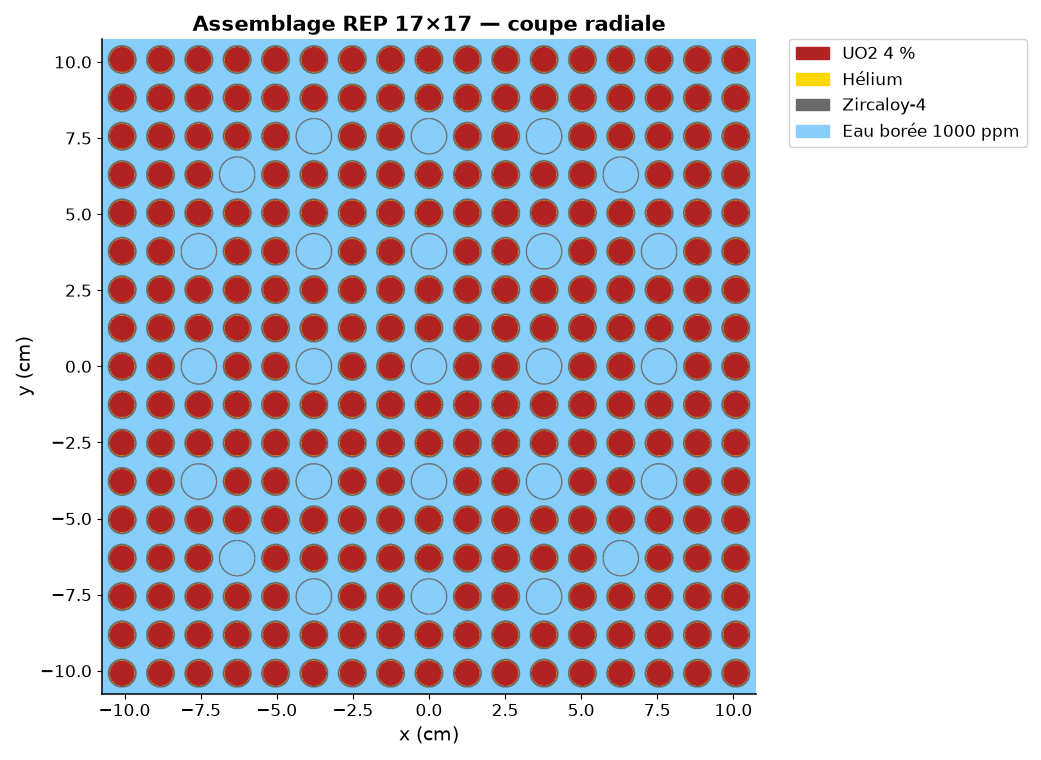

In [3]:
# Modèle principal : source uniforme dans le combustible (réglages statistiques en partie 3)
STATISTIQUE = dict(particules=50_000, generations=450, inactives=50, graine=1)   # 20 M d'histoires actives
modele, cellules = modele_assemblage(**STATISTIQUE)
modele.settings.entropy_mesh = maillage_crayons()
combustible, helium, gaine, eau = modele.materials

donnees, _ = modele.slice_data(width=(PAS_ASSEMBLAGE, PAS_ASSEMBLAGE), pixels=(2000, 2000), show_overlaps=True)
n_problemes = int((donnees[..., 0] < 0).sum())
print(f"Pixels sans cellule ou en chevauchement : {n_problemes} / {donnees[..., 0].size}")
assert n_problemes == 0, "Géométrie incorrecte"

couleurs = {combustible: "firebrick", helium: "gold", gaine: "dimgray", eau: "lightskyblue"}
fig, ax = plt.subplots(figsize=(10, 8.5))
modele.plot(width=(PAS_ASSEMBLAGE, PAS_ASSEMBLAGE), pixels=(1500, 1500), color_by="material",
            colors=couleurs, legend=True, axes=ax)
ax.grid(False)
ax.set_title("Assemblage REP 17×17 — coupe radiale")
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.figure.savefig(DOSSIER_RESULTATS / "geometrie.png", bbox_inches="tight")
plt.show()

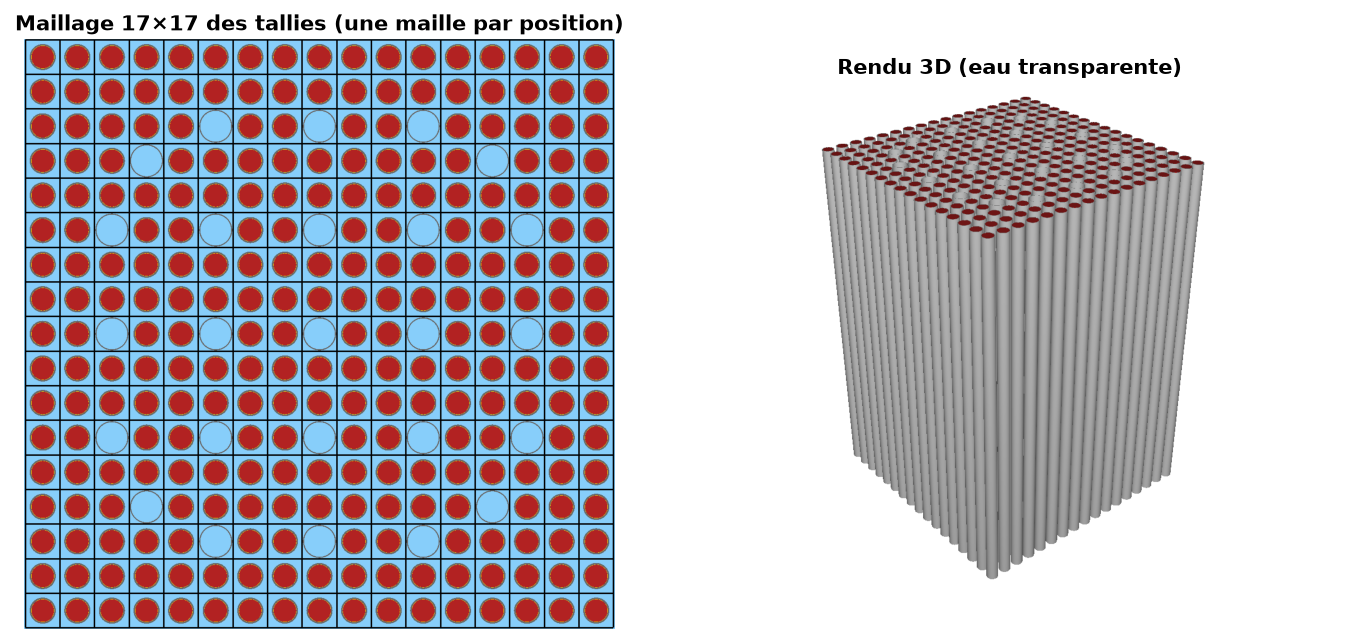

In [4]:
# Traceur intégré : maillage des tallies superposé, et rendu 3D (assemblage plus haut, pour l'image seulement)
coupe = openmc.SlicePlot()
coupe.filename = "coupe_maillage"
coupe.width = (PAS_ASSEMBLAGE, PAS_ASSEMBLAGE)
coupe.pixels = (1200, 1200)
coupe.color_by = "material"
coupe.colors = couleurs
coupe.meshlines = {"type": "entropy", "linewidth": 1, "color": (0, 0, 0)}

materiaux_3d = [combustible_uo2(), helium_jeu(), zircaloy4(), eau_boree(1000)]
geometrie_3d, _ = assemblage_17x17(*materiaux_3d, hauteur=30.0)
modele_3d = openmc.Model(geometry=geometrie_3d, materials=openmc.Materials(materiaux_3d), settings=modele.settings)
rendu = openmc.SolidRayTracePlot()
rendu.filename = "rendu_3d"
rendu.pixels = (1200, 900)
rendu.color_by = "material"
rendu.colors = dict(zip(materiaux_3d, ["firebrick", "gold", "silver", "lightskyblue"]))
rendu.opaque_domains = [materiaux_3d[0], materiaux_3d[2]]   # combustible et Zircaloy opaques, eau transparente
rendu.camera_position = (55, -45, 42)
rendu.look_at = (0, 0, -1)
rendu.horizontal_field_of_view = 38
rendu.diffuse_fraction = 0.35

dossier_images = DOSSIER_CALCUL / "images"
modele.plots = openmc.Plots([coupe])
modele.plot_geometry(cwd=dossier_images, output=False)
modele_3d.plots = openmc.Plots([rendu])
modele_3d.plot_geometry(cwd=dossier_images, output=False)
modele.plots = openmc.Plots()   # on retire les tracés du modèle de calcul

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5))
ax1.imshow(plt.imread(dossier_images / "coupe_maillage.png"))
ax1.set_title("Maillage 17×17 des tallies (une maille par position)")
ax2.imshow(plt.imread(dossier_images / "rendu_3d.png"))
ax2.set_title("Rendu 3D (eau transparente)")
for ax in (ax1, ax2):
    ax.axis("off")
fig.tight_layout()
plt.show()
plt.imsave(DOSSIER_RESULTATS / "rendu_3d.png", plt.imread(dossier_images / "rendu_3d.png"))

## 3. Calcul principal

### Statistique

Pour une carte de puissance, chaque crayon doit être estimé avec précision, pas seulement k. Les 264 crayons se
partagent les fissions : chacun n'en reçoit qu'environ 0,4 %. On utilise donc beaucoup plus d'histoires que pour la
cellule crayon : 50 000 neutrons × 400 générations actives = **20 millions d'histoires** (environ 5 min). Les
50 générations inactives sont largement suffisantes pour un assemblage seul (on le vérifiera en partie 5).

### Tallies

Sur le maillage 17×17 :
- la **puissance** de chaque crayon : score `kappa-fission` (énergie récupérable libérée par les fissions, ≈ 200 MeV
  par fission) ;
- le **flux thermique** (< 0,625 eV) moyen dans chaque maille, pour comprendre la carte de puissance.

In [5]:
filtre_crayons = openmc.MeshFilter(maillage_crayons())

tally_puissance = openmc.Tally(name="puissance")
tally_puissance.filters = [filtre_crayons]
tally_puissance.scores = ["kappa-fission"]

tally_flux = openmc.Tally(name="flux_thermique")
tally_flux.filters = [filtre_crayons, openmc.EnergyFilter([1e-5, 0.625])]
tally_flux.scores = ["flux"]

modele.tallies = openmc.Tallies([tally_puissance, tally_flux])
resultat = calculer_k(modele, DOSSIER_CALCUL / "principal")
print(f"Calcul : {resultat['duree']:.0f} s" + (" (résultat réutilisé)" if resultat["reutilise"] else ""))

Calcul : 0 s (résultat réutilisé)


## 4. Résultats

### 4.1 k∞ de l'assemblage et comparaison avec la cellule crayon

In [6]:
k_ass, s_ass = resultat["k"], resultat["sigma"]
cellule_crayon = pd.read_csv(RACINE / "results" / "01_pin_cell" / "resume.csv").iloc[0]
k_pin, s_pin = cellule_crayon.k_inf, cellule_crayon.sigma_k
ecart = (k_ass - k_pin) * 1e5
s_ecart = np.hypot(s_ass, s_pin) * 1e5
print(f"k∞ assemblage     = {k_ass:.5f} ± {s_ass:.5f}")
print(f"k∞ cellule crayon = {k_pin:.5f} ± {s_pin:.5f}   (notebook 01, mêmes conditions)")
print(f"Écart             = {ecart:+.0f} ± {s_ecart:.0f} pcm")

volume_eau_crayon = PAS**2 - np.pi * 0.475**2
volume_comb = np.pi * 0.4096**2
print(f"\nRapport de modération V_eau/V_comb : cellule crayon {volume_eau_crayon / volume_comb:.2f}, "
      f"assemblage {(PAS_ASSEMBLAGE**2 - 264 * np.pi * 0.475**2 - 25 * np.pi * (0.602**2 - 0.561**2)) / (264 * volume_comb):.2f}")

k∞ assemblage     = 1.27391 ± 0.00022
k∞ cellule crayon = 1.26468 ± 0.00055   (notebook 01, mêmes conditions)
Écart             = +923 ± 59 pcm

Rapport de modération V_eau/V_comb : cellule crayon 1.67, assemblage 1.95


**Lecture.** L'assemblage est plus réactif que la cellule crayon, d'environ **920 ± 60 pcm**. Les 25 tubes (24 tubes
guides et le tube d'instrumentation) prennent la place de crayons et sont pleins d'eau : il y a plus d'eau par crayon
combustible (rapport de modération 1,95 contre 1,67). Or le réseau est **sous-modéré** (notebook 02b) : à 1000 ppm, le
coefficient du modérateur est encore négatif (≈ −18 pcm/K), c'est-à-dire que retirer de l'eau fait baisser la
réactivité ; en ajouter l'augmente. Le surcroît de modération l'emporte sur les captures supplémentaires dans le bore
et dans le Zircaloy des tubes.

### 4.2 Carte de puissance crayon par crayon

La puissance de chaque crayon est normalisée à une **moyenne de 1** sur les 264 crayons combustibles. Les positions des
tubes guides (sans combustible, donc sans puissance) sont masquées.

In [7]:
with openmc.StatePoint(resultat["statepoint"]) as sp:
    t = sp.get_tally(name="puissance")
    P = t.mean.ravel().reshape(N, N)            # [y, x], y croissant vers le haut
    sP = t.std_dev.ravel().reshape(N, N)
    tf = sp.get_tally(name="flux_thermique")
    phi_th = tf.mean.ravel().reshape(N, N)
    k_generations = np.array(sp.k_generation)
    entropie_principale = np.array(sp.entropy)

combustible_present = P > 0
assert combustible_present.sum() == 264
moyenne = P[combustible_present].mean()
puissance = np.where(combustible_present, P / moyenne, np.nan)
incertitude = np.where(combustible_present, sP / np.where(combustible_present, P, 1.0), np.nan)   # relative

F_xy = np.nanmax(puissance)
j_max, i_max = np.unravel_index(np.nanargmax(puissance), puissance.shape)
j_min, i_min = np.unravel_index(np.nanargmin(puissance), puissance.shape)
print(f"Facteur de point chaud F_xy = {F_xy:.4f}  (crayon x={i_max}, y={j_max})")
print(f"Crayon le moins puissant    = {np.nanmin(puissance):.4f}  (crayon x={i_min}, y={j_min})")
print(f"Incertitude relative par crayon : moyenne {np.nanmean(incertitude):.2%}, max {np.nanmax(incertitude):.2%}")

Facteur de point chaud F_xy = 1.0612  (crayon x=13, y=12)
Crayon le moins puissant    = 0.9274  (crayon x=1, y=15)
Incertitude relative par crayon : moyenne 0.29%, max 0.36%


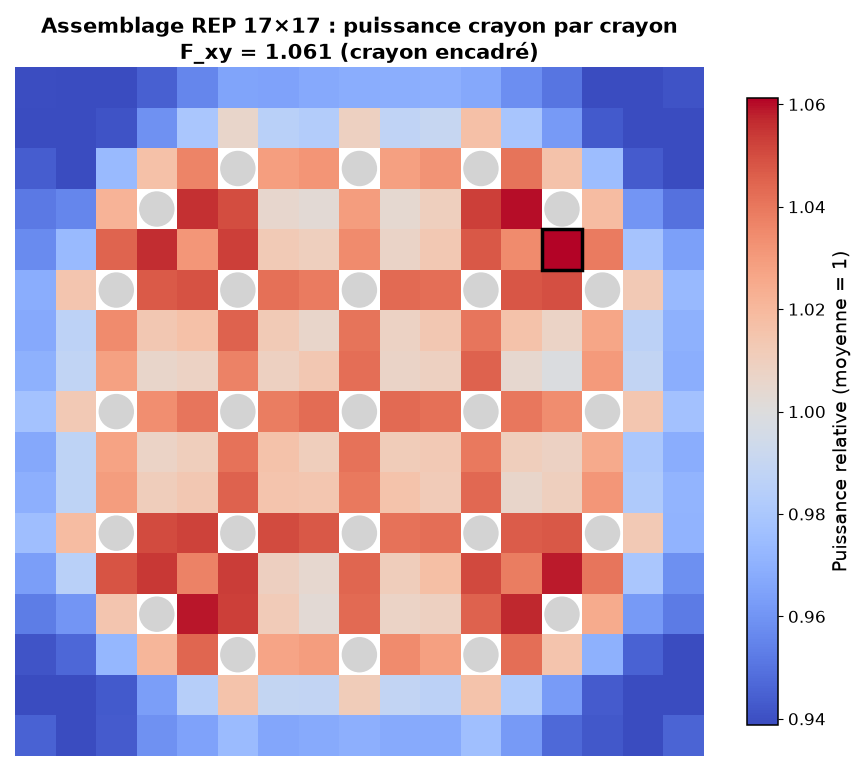

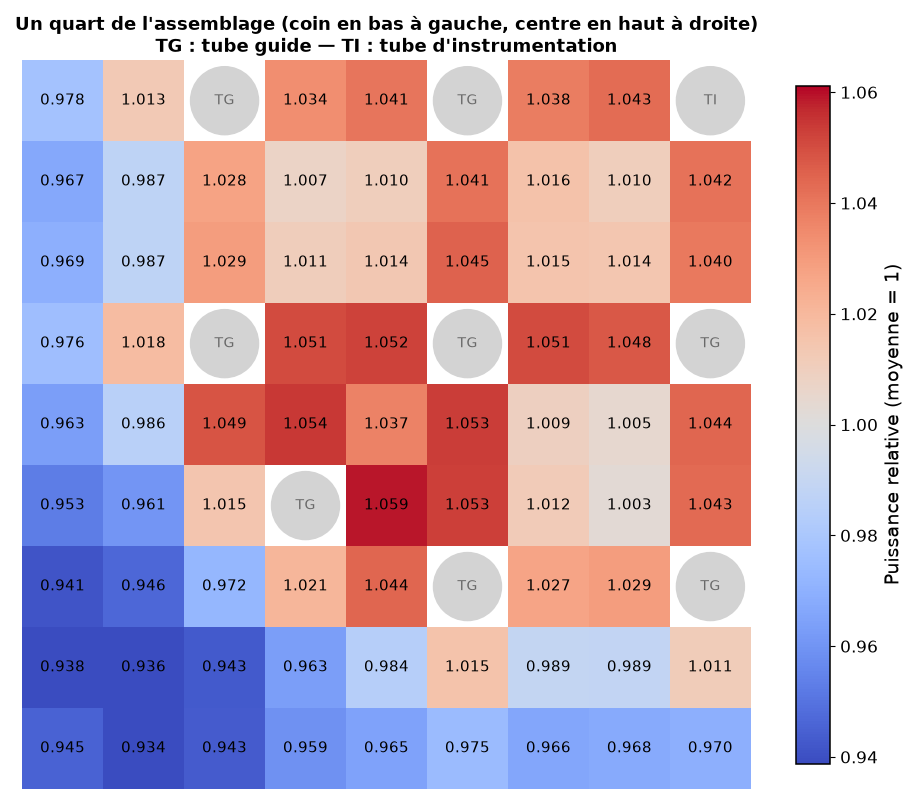

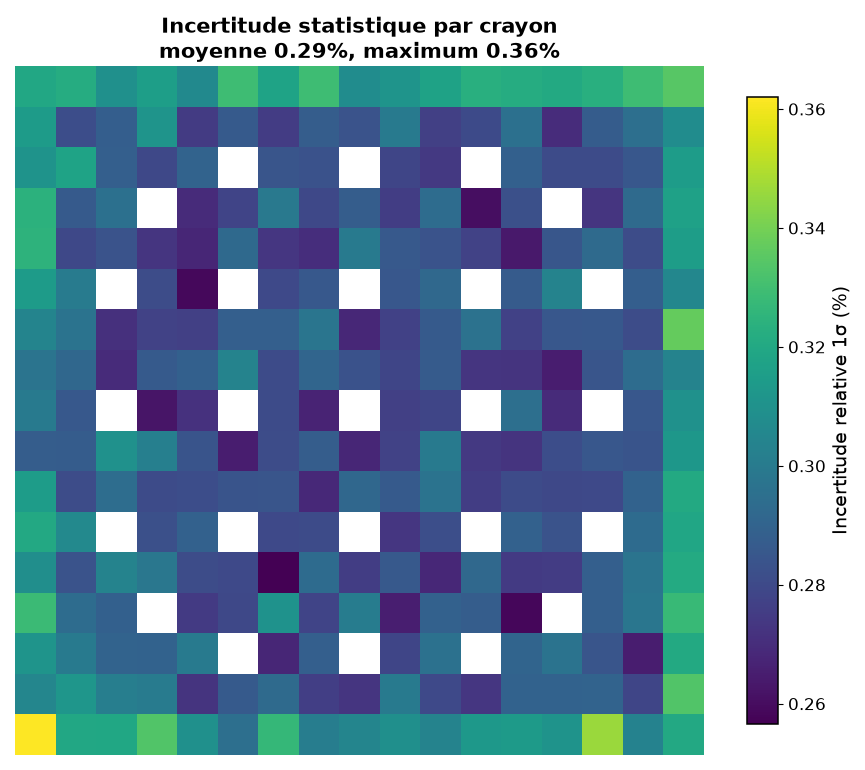

In [8]:
def dessiner_carte(ax, valeurs, cmap, vmin, vmax):
    im = ax.imshow(valeurs, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    return im


# --- Figure 1 : carte complète (lisible en petit format : pas de chiffres)
fig, ax = plt.subplots(figsize=(9, 8))
im = dessiner_carte(ax, puissance, "coolwarm", 2 - F_xy, F_xy)
for j, i in np.argwhere(~combustible_present):
    ax.add_patch(plt.Circle((i, j), 0.42, color="lightgray", zorder=3))
ax.add_patch(plt.Rectangle((i_max - 0.5, j_max - 0.5), 1, 1, fill=False, lw=2.5, ec="black", zorder=4))
fig.colorbar(im, ax=ax, shrink=0.85, label="Puissance relative (moyenne = 1)")
ax.set_title(f"Assemblage REP 17×17 : puissance crayon par crayon\nF_xy = {F_xy:.3f} (crayon encadré)")
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "carte_puissance.png")
plt.show()

# --- Figure 2 : un quart de l'assemblage, avec les valeurs (la carte est symétrique)
quart = slice(0, N // 2 + 1)
fig, ax = plt.subplots(figsize=(9.5, 8.5))
im = dessiner_carte(ax, puissance[quart, quart], "coolwarm", 2 - F_xy, F_xy)
for j in range(N // 2 + 1):
    for i in range(N // 2 + 1):
        if combustible_present[j, i]:
            ax.text(i, j, f"{puissance[j, i]:.3f}", ha="center", va="center", fontsize=10.5)
        else:
            ax.add_patch(plt.Circle((i, j), 0.42, color="lightgray", zorder=3))
            ax.text(i, j, "TI" if (i, j) == (N // 2, N // 2) else "TG", ha="center", va="center",
                    fontsize=10, color="dimgray", zorder=4)
fig.colorbar(im, ax=ax, shrink=0.85, label="Puissance relative (moyenne = 1)")
ax.set_title("Un quart de l'assemblage (coin en bas à gauche, centre en haut à droite)\n"
             "TG : tube guide — TI : tube d'instrumentation", fontsize=13)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "carte_puissance_quart.png")
plt.show()

# --- Figure 3 : incertitude statistique par crayon
fig, ax = plt.subplots(figsize=(9, 8))
im = dessiner_carte(ax, incertitude * 100, "viridis", None, None)
fig.colorbar(im, ax=ax, shrink=0.85, label="Incertitude relative 1σ (%)")
ax.set_title(f"Incertitude statistique par crayon\nmoyenne {np.nanmean(incertitude):.2%}, "
             f"maximum {np.nanmax(incertitude):.2%}")
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "incertitude_puissance.png")
plt.show()

pd.DataFrame(puissance).to_csv(DOSSIER_RESULTATS / "carte_puissance.csv", index=False, float_format="%.5f")

**Lecture.**
- **F_xy ≈ 1,061** : le crayon le plus puissant produit 6 % de plus que la moyenne ; le moins puissant (≈ 0,927) 7 % de
  moins. Avec une incertitude d'environ 0,3 % par crayon, ces écarts sont très largement significatifs.
- Les crayons les plus puissants sont les **voisins immédiats des tubes guides** : ces « trous d'eau » sur-modèrent
  localement le réseau (section 4.4).
- Les **rangées périphériques** sont les moins puissantes : elles sont loin de tout tube guide, et la lame d'eau entre
  assemblages (0,8 mm au total) est trop fine pour compenser. Les crayons de coin sont un peu plus puissants que leurs
  voisins de bord, probablement parce qu'ils bordent cette lame d'eau sur deux côtés.
- L'incertitude est plus grande en périphérie : moins de fissions y ont lieu, donc moins d'événements comptés.

### 4.3 Test de symétrie

L'assemblage est symétrique au huitième : un crayon a jusqu'à 7 « jumeaux » obtenus par les miroirs horizontal,
vertical et diagonaux. Ils doivent avoir la **même puissance** aux fluctuations statistiques près. C'est un test
gratuit de la cohérence des résultats et de leurs incertitudes : pour chaque crayon, on calcule l'écart à la moyenne de
son groupe de jumeaux, en nombre de σ. Si les incertitudes sont correctes, ces écarts doivent suivre une loi normale
centrée réduite (≈ 68 % à moins de 1σ, ≈ 95 % à moins de 2σ).

39 groupes de jumeaux, 264 crayons testés
Écart-type des écarts : 1.09   (attendu ≈ 1)
À moins de 1σ : 63% (attendu ≈ 68 %) — à moins de 2σ : 94% (attendu ≈ 95 %) — plus grand écart : 3.1σ


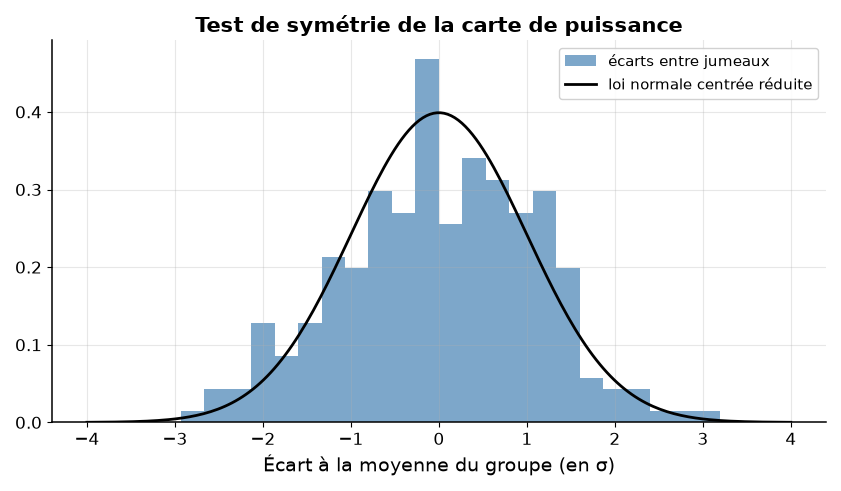

In [9]:
def jumeaux(i, j, n=N - 1):
    return {(i, j), (n - i, j), (i, n - j), (n - i, n - j), (j, i), (n - j, i), (j, n - i), (n - j, n - i)}


ecarts, groupes_vus = [], set()
for j in range(N):
    for i in range(N):
        if not combustible_present[j, i]:
            continue
        groupe = frozenset(jumeaux(i, j))
        if groupe in groupes_vus or len(groupe) < 2:
            continue
        groupes_vus.add(groupe)
        valeurs = np.array([P[b, a] for a, b in groupe])
        sigmas = np.array([sP[b, a] for a, b in groupe])
        moyenne_groupe = np.average(valeurs, weights=1 / sigmas**2)
        # écart de chaque crayon à la moyenne de son groupe ; le facteur corrige la part de lui-même dans la moyenne
        ecarts += list((valeurs - moyenne_groupe) / sigmas / np.sqrt(1 - 1 / len(valeurs)))

ecarts = np.array(ecarts)
print(f"{len(groupes_vus)} groupes de jumeaux, {len(ecarts)} crayons testés")
print(f"Écart-type des écarts : {ecarts.std():.2f}   (attendu ≈ 1)")
print(f"À moins de 1σ : {np.mean(np.abs(ecarts) < 1):.0%} (attendu ≈ 68 %) — à moins de 2σ : "
      f"{np.mean(np.abs(ecarts) < 2):.0%} (attendu ≈ 95 %) — plus grand écart : {np.abs(ecarts).max():.1f}σ")

fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.linspace(-4, 4, 200)
ax.hist(ecarts, bins=30, range=(-4, 4), density=True, color="steelblue", alpha=0.7, label="écarts entre jumeaux")
ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color="k", label="loi normale centrée réduite")
ax.set_xlabel("Écart à la moyenne du groupe (en σ)")
ax.legend(fontsize=11)
ax.set_title("Test de symétrie de la carte de puissance")
fig.tight_layout()
plt.show()

**Lecture.** La distribution des écarts entre crayons symétriques est proche de la loi normale attendue (63 % à moins
de 1σ, 94 % à moins de 2σ ; un seul crayon au-delà de 3σ, ce qui est plausible sur 264). La carte est donc cohérente
avec la symétrie de l'assemblage. L'écart-type (≈ 1,09 au lieu de 1) indique un léger excès de dispersion, d'environ
deux fois l'incertitude de cette estimation : les incertitudes par crayon fournies par OpenMC sont peut-être un peu
sous-estimées, ce qui serait cohérent avec la corrélation entre générations étudiée en partie 5.3.

### 4.4 Pourquoi cette carte ? Le flux thermique

La puissance d'un crayon est proportionnelle au taux de fission, donc, pour l'essentiel, au **flux thermique** qui le
traverse (les fissions de l'U-235 sont surtout thermiques). On compare donc la carte de puissance au flux thermique
moyen dans chaque maille.

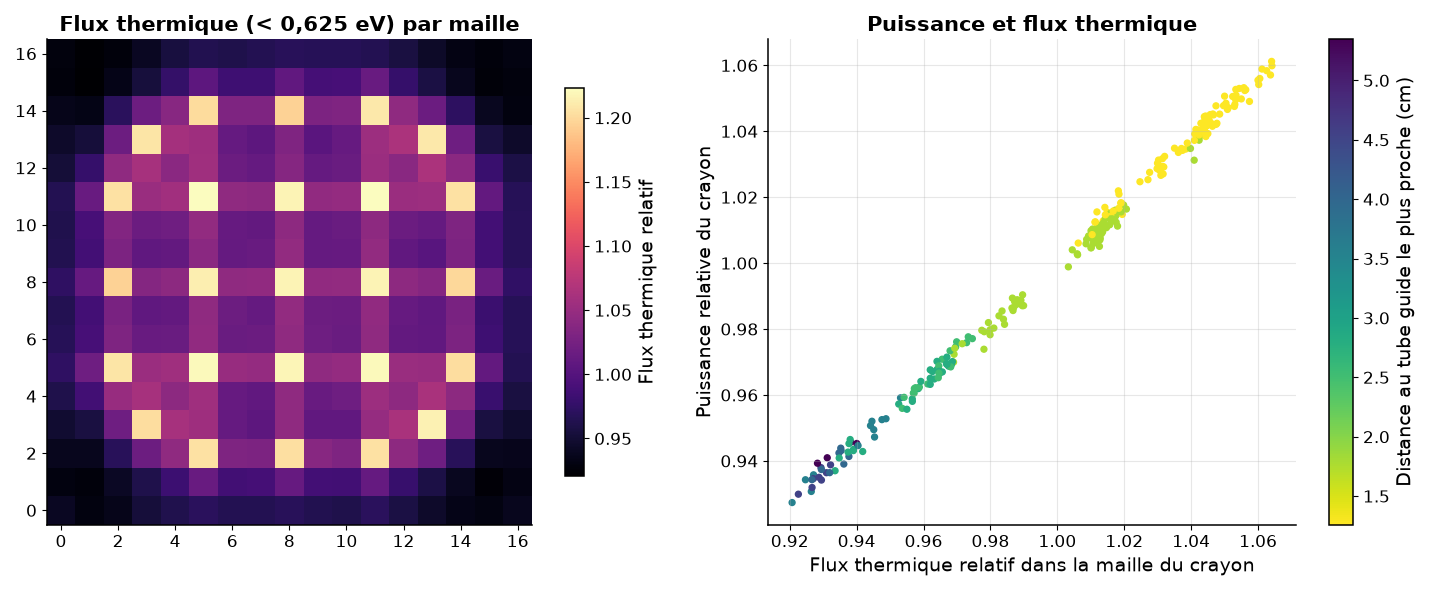

Coefficient de corrélation puissance / flux thermique : 0.998
Crayons à 0.0–1.3 cm d'un tube guide : 100 crayons, puissance moyenne 1.0369
Crayons à 1.3–1.8 cm d'un tube guide :  80 crayons, puissance moyenne 1.0017
Crayons à 1.8–10.0 cm d'un tube guide :  84 crayons, puissance moyenne 0.9545


In [10]:
phi_rel = phi_th / phi_th[combustible_present].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
im = ax1.imshow(phi_rel, origin="lower", cmap="magma")
ax1.grid(False)
fig.colorbar(im, ax=ax1, shrink=0.8, label="Flux thermique relatif")
ax1.set_title("Flux thermique (< 0,625 eV) par maille")

# Distance de chaque crayon au tube guide le plus proche
tubes = np.argwhere(~combustible_present)
distance = np.full((N, N), np.nan)
for j, i in np.argwhere(combustible_present):
    distance[j, i] = np.min(np.hypot(tubes[:, 0] - j, tubes[:, 1] - i)) * PAS
sc = ax2.scatter(phi_rel[combustible_present], puissance[combustible_present], c=distance[combustible_present],
                 cmap="viridis_r", s=18)
fig.colorbar(sc, ax=ax2, label="Distance au tube guide le plus proche (cm)")
ax2.set_xlabel("Flux thermique relatif dans la maille du crayon")
ax2.set_ylabel("Puissance relative du crayon")
ax2.set_title("Puissance et flux thermique")
ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "flux_thermique.png", bbox_inches="tight")
plt.show()

coef_correlation = np.corrcoef(phi_rel[combustible_present], puissance[combustible_present])[0, 1]
print(f"Coefficient de corrélation puissance / flux thermique : {coef_correlation:.3f}")
for d_min, d_max in [(0, 1.3), (1.3, 1.8), (1.8, 10)]:
    sel = combustible_present & (distance >= d_min) & (distance < d_max)
    print(f"Crayons à {d_min:.1f}–{d_max:.1f} cm d'un tube guide : {sel.sum():3d} crayons, "
          f"puissance moyenne {np.nanmean(puissance[sel]):.4f}")

**Lecture.** La puissance suit presque parfaitement le flux thermique (corrélation ≈ 0,998). Les crayons adjacents à un
tube guide (à 1,26 cm) ont une puissance moyenne d'environ 1,037, ceux en diagonale (1,78 cm) environ 1,002, et les
crayons plus éloignés environ 0,955. Dans un tube guide, les neutrons trouvent de l'eau sans combustible pour les
absorber : ils s'y thermalisent, puis provoquent des fissions dans les crayons voisins.

Conséquence pratique : en conception, on répartit les tubes guides pour aplatir la nappe de puissance, et on limite
F_xy, car c'est le crayon le plus chaud qui fixe la marge de sûreté thermique de tout l'assemblage.

## 5. Convergence de la source de fission

L'exemple officiel *Source Convergence* montre, sur un cœur complet, qu'un nombre de générations inactives choisi à
l'avance peut être insuffisant, et que l'**entropie de Shannon** permet de le détecter (notebook 01, section 4). On
reprend la démarche, mais avec un critère chiffré, sur deux systèmes de tailles très différentes.

**Critère de stabilisation** : on estime la valeur finale de l'entropie et sa dispersion sur la seconde moitié du
calcul ; la source est considérée comme convergée à partir de la première génération où la moyenne glissante sur
10 générations tombe dans ± 2 écarts-types de la valeur finale.

In [11]:
def generation_stabilisation(entropie, fenetre=10):
    fin = entropie[len(entropie) // 2:]
    for g in range(len(entropie) - fenetre):
        if abs(entropie[g:g + fenetre].mean() - fin.mean()) < 2 * fin.std():
            return g + 1
    return None


def lancer_convergence(modele_conv, nom):
    r = calculer_k(modele_conv, DOSSIER_CALCUL / nom)
    with openmc.StatePoint(r["statepoint"]) as sp:
        return np.array(sp.entropy), np.array(sp.k_generation), sp.n_inactive

### 5.1 Assemblage seul : source dans un coin ou source uniforme

On part soit d'une source **uniforme** dans le combustible (le choix raisonnable), soit d'une source **ponctuelle**
dans le crayon d'un coin (un très mauvais choix), avec 10 000 neutrons par génération.

In [12]:
CONVERGENCE = dict(particules=10_000, generations=150, inactives=50, graine=1)
coin = (-(N // 2) * PAS, -(N // 2) * PAS, 0.0)
entropies_ass, k_ass_gen = {}, {}
for nom, source in [("uniforme", None), ("coin", coin)]:
    m, _ = modele_assemblage(source_ponctuelle=source, **CONVERGENCE)
    m.settings.entropy_mesh = maillage_crayons()
    entropies_ass[nom], k_ass_gen[nom], _ = lancer_convergence(m, f"convergence_assemblage_{nom}")
    print(f"Source {nom:8s} : entropie stabilisée à la génération {generation_stabilisation(entropies_ass[nom])}, "
          f"entropie finale {entropies_ass[nom][75:].mean():.3f} bits (maximum log2(264) = {np.log2(264):.3f})")

Source uniforme : entropie stabilisée à la génération 1, entropie finale 8.012 bits (maximum log2(264) = 8.044)
Source coin     : entropie stabilisée à la génération 3, entropie finale 8.013 bits (maximum log2(264) = 8.044)


### 5.2 Rangée de 9 assemblages avec fuites : un système « grand »

Pour un système grand devant le parcours des neutrons, on construit une **rangée de 9 assemblages** (≈ 1,9 m) selon x,
avec des **fuites** (frontières de vide) aux deux extrémités, et réfléchissante en y et en z : une bande de cœur. La
source initiale est un point dans l'assemblage d'une extrémité. On utilise 300 générations dont 100 inactives, et un
maillage d'entropie de 45 mailles selon x (5 par assemblage).

In [13]:
N_ASSEMBLAGES = 9
longueur = N_ASSEMBLAGES * PAS_ASSEMBLAGE
modele_ligne, _ = modele_rangee(N_ASSEMBLAGES, source_ponctuelle=(-longueur / 2 + PAS_ASSEMBLAGE / 2, 0.63, 0.0),
                                particules=10_000, generations=300, inactives=100, graine=1)
maillage_ligne = openmc.RegularMesh()
maillage_ligne.lower_left = (-longueur / 2, -PAS_ASSEMBLAGE / 2, -HAUTEUR / 2)
maillage_ligne.upper_right = (longueur / 2, PAS_ASSEMBLAGE / 2, HAUTEUR / 2)
maillage_ligne.dimension = (5 * N_ASSEMBLAGES, 1, 1)
modele_ligne.settings.entropy_mesh = maillage_ligne

entropie_ligne, k_ligne, inactives_ligne = lancer_convergence(modele_ligne, "convergence_rangee")
g_stab = generation_stabilisation(entropie_ligne)
print(f"Entropie stabilisée à la génération {g_stab}")
print("k moyen par paquets de 20 générations (1–100) :",
      np.round([k_ligne[i:i + 20].mean() for i in range(0, 100, 20)], 4),
      f"| générations actives : {k_ligne[inactives_ligne:].mean():.4f}")

Entropie stabilisée à la génération 55
k moyen par paquets de 20 générations (1–100) : [1.1907 1.2466 1.2541 1.2577 1.2515] | générations actives : 1.2565


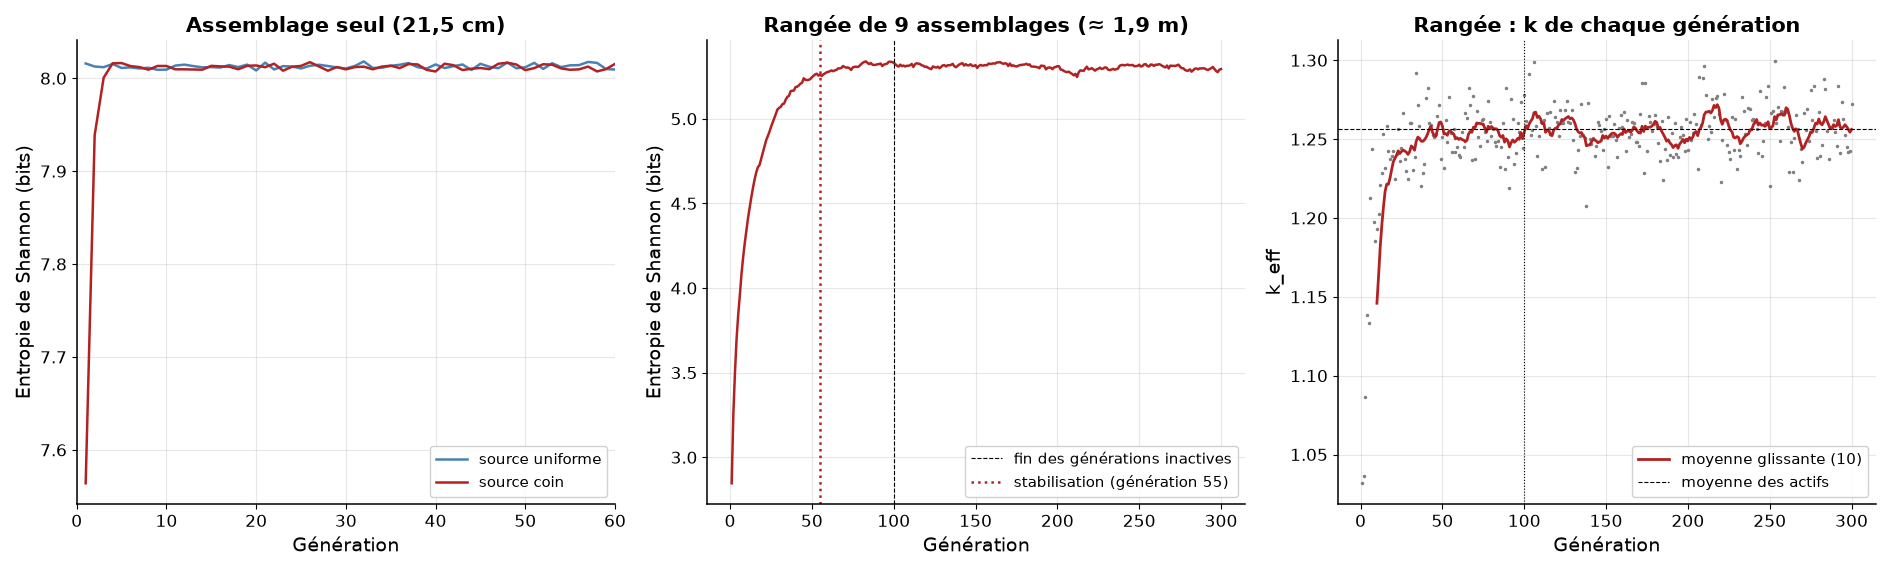

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))

for nom, couleur in [("uniforme", "steelblue"), ("coin", "firebrick")]:
    axes[0].plot(np.arange(1, 151), entropies_ass[nom], color=couleur, lw=1.8, label=f"source {nom}")
axes[0].set_title("Assemblage seul (21,5 cm)")
axes[0].set_xlim(0, 60)

axes[1].plot(np.arange(1, len(entropie_ligne) + 1), entropie_ligne, color="firebrick", lw=1.8)
axes[1].axvline(inactives_ligne, color="k", ls="--", lw=0.8, label="fin des générations inactives")
if g_stab:
    axes[1].axvline(g_stab, color="firebrick", ls=":", lw=1.8, label=f"stabilisation (génération {g_stab})")
axes[1].set_title(f"Rangée de {N_ASSEMBLAGES} assemblages (≈ {longueur / 100:.1f} m)".replace(".", ","))

axes[2].plot(np.arange(1, len(k_ligne) + 1), k_ligne, ".", ms=3, color="gray")
moyenne_glissante = np.convolve(k_ligne, np.ones(10) / 10, mode="valid")
axes[2].plot(np.arange(10, len(k_ligne) + 1), moyenne_glissante, color="firebrick", label="moyenne glissante (10)")
axes[2].axhline(k_ligne[inactives_ligne:].mean(), color="k", ls="--", lw=0.8, label="moyenne des actifs")
axes[2].axvline(inactives_ligne, color="k", ls=":", lw=0.8)
axes[2].set_title("Rangée : k de chaque génération")
axes[2].set_ylabel("k_eff")

for ax in axes[:2]:
    ax.set_ylabel("Entropie de Shannon (bits)")
for ax in axes:
    ax.set_xlabel("Génération")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "convergence.png", bbox_inches="tight")
plt.show()

**Lecture.**
- **Assemblage seul** : même partie d'un seul crayon dans un coin, la source est convergée en **3 générations**
  (l'entropie passe de 7,56 à 8,01 bits). L'assemblage (21,5 cm, bords réfléchissants) est petit devant la distance que
  parcourt un neutron de sa naissance à sa disparition : en quelques générations, les neutrons ont « visité » tout le
  système. Les 50 générations inactives du calcul principal étaient donc une large marge.
- **Rangée de 9 assemblages** : la source met environ **55 générations** à se stabiliser, et k est fortement biaisé
  au départ (≈ 1,19 en moyenne sur les 20 premières générations, contre ≈ 1,257 une fois la source convergée). Avec
  seulement 20 ou 30 générations inactives, ce biais aurait contaminé le résultat.
- C'est la leçon de l'exemple officiel : **le nombre de générations inactives se choisit d'après l'entropie, pas a
  priori**. La lenteur dépend du **rapport de dominance** : dans un grand système faiblement couplé (comme un cœur
  complet, ou notre rangée), le mode fondamental de la source se distingue mal des modes suivants, et ces derniers
  s'éteignent lentement d'une génération à l'autre.

### 5.3 Corrélation entre générations : la méthode des blocs

L'incertitude donnée par OpenMC suppose les générations actives **indépendantes**. Or la source d'une génération est
issue de la précédente : les générations successives peuvent être corrélées. Pour le tester sans hypothèse, on regroupe
les générations actives en **blocs** de $b$ générations consécutives, on calcule la moyenne de chaque bloc, et on en
déduit l'incertitude de la moyenne générale à partir de la dispersion des blocs :

- si les générations sont indépendantes, le résultat ne dépend pas de $b$ ;
- si elles sont positivement corrélées, l'incertitude **augmente** avec $b$ puis plafonne : la valeur du plateau est la
  vraie incertitude, et le rapport au cas $b = 1$ mesure la sous-estimation de l'incertitude naïve.

assemblage (calcul principal)    : autocorrélation (décalage 1) = +0.02 ; σ(blocs de 20) / σ(naïf) = 1.13  (400 générations actives)
rangée de 9 assemblages          : autocorrélation (décalage 1) = +0.04 ; σ(blocs de 20) / σ(naïf) = 1.43  (200 générations actives)


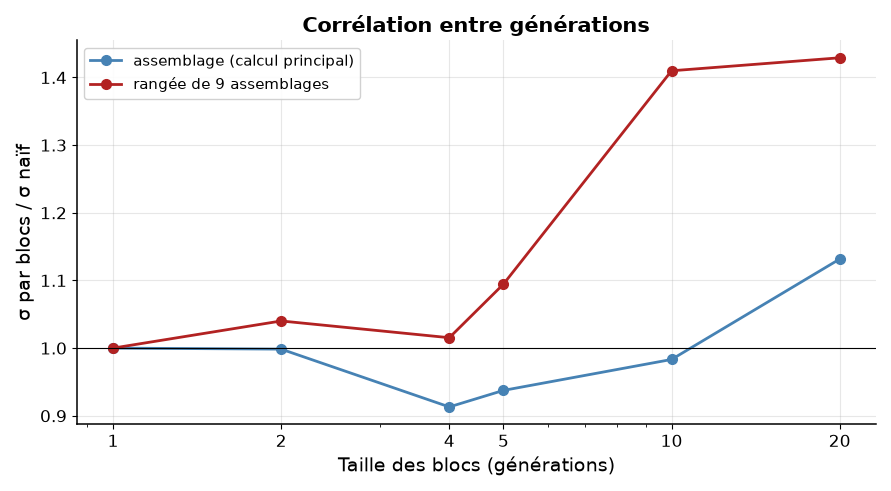

In [15]:
def ecart_type_par_blocs(x, taille):
    n = len(x) // taille
    blocs = x[:n * taille].reshape(n, taille).mean(axis=1)
    return blocs.std(ddof=1) / np.sqrt(n)


def autocorrelation(x, decalage=1):
    e = x - x.mean()
    return np.sum(e[decalage:] * e[:-decalage]) / np.sum(e**2)


series = {
    "assemblage (calcul principal)": k_generations[STATISTIQUE["inactives"]:],
    f"rangée de {N_ASSEMBLAGES} assemblages": k_ligne[inactives_ligne:],
}
tailles = [1, 2, 4, 5, 10, 20]
fig, ax = plt.subplots(figsize=(9, 5))
for (nom, x), couleur in zip(series.items(), ["steelblue", "firebrick"]):
    rapports = [ecart_type_par_blocs(x, b) / ecart_type_par_blocs(x, 1) for b in tailles]
    ax.plot(tailles, rapports, "o-", color=couleur, label=nom)
    print(f"{nom:32s} : autocorrélation (décalage 1) = {autocorrelation(x):+.2f} ; "
          f"σ(blocs de 20) / σ(naïf) = {rapports[-1]:.2f}  ({len(x)} générations actives)")
ax.axhline(1, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_xticks(tailles)
ax.set_xticklabels(tailles)
ax.set_xlabel("Taille des blocs (générations)")
ax.set_ylabel("σ par blocs / σ naïf")
ax.set_title("Corrélation entre générations")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Lecture.**
- **Assemblage** : le rapport σ(blocs)/σ(naïf) reste proche de 1 (≈ 1,13 avec 20 blocs, une valeur compatible avec 1
  car l'estimation d'un écart-type sur 20 blocs est elle-même incertaine d'environ ± 16 %). Les générations sont
  quasi indépendantes : l'incertitude d'OpenMC est fiable.
- **Rangée** : le rapport atteint ≈ 1,43 avec 10 blocs (incertitude de l'estimation ≈ ± 24 %) : c'est un **indice**
  que l'incertitude naïve sous-estime l'incertitude réelle d'environ 40 % dans le grand système, comme attendu, mais
  pas une preuve. L'autocorrélation entre générations voisines est pourtant faible (≈ +0,04) : la corrélation porterait
  plutôt sur des fluctuations lentes, sur plusieurs dizaines de générations. Il faudrait beaucoup plus de générations
  actives pour conclure.

## 6. Bilan

- **Géométrie** : assemblage 17×17 construit à partir d'univers et d'un réseau, sans chevauchement ; visualisé en coupe,
  avec le maillage des tallies superposé, et en 3D.
- **k∞ de l'assemblage** : environ 1,274, soit ≈ 920 pcm de plus que la cellule crayon, à cause de l'eau des tubes
  guides dans un réseau sous-modéré.
- **Carte de puissance** : F_xy ≈ 1,061, avec une incertitude d'environ 0,3 % par crayon ; les crayons voisins des
  tubes guides sont les plus puissants, la périphérie la moins puissante. La carte respecte la symétrie de
  l'assemblage, et suit le flux thermique (corrélation ≈ 0,998).
- **Convergence** : immédiate dans un assemblage seul, lente (≈ 55 générations) dans une rangée de 9 assemblages, où
  un nombre de générations inactives insuffisant biaiserait k de plusieurs milliers de pcm. Dans ce grand système,
  la méthode des blocs suggère aussi que l'incertitude naïve est sous-estimée.

**Suite** : notebook 04, épuisement du combustible.

## Sources

- Documentation OpenMC 0.16 : `openmc.RectLattice`, `openmc.MeshFilter`, `openmc.SlicePlot`,
  `openmc.SolidRayTracePlot`, `Settings.entropy_mesh`, <https://docs.openmc.org/>.
- Exemple officiel *Source Convergence* (atelier OpenMC, P. Romano) : entropie de Shannon et choix du nombre de
  générations inactives.
- P. Reuss, *Précis de neutronique*, EDP Sciences : réseaux, trous d'eau, facteurs de forme de puissance.